In [6]:
import anndata as ad
import geopandas as gpd
import os
import pandas as pd
import pickle
import scanpy as sc
from shapely.geometry import Polygon, Point, box
import gc

# Step 1: Find which nuclei fall into which patch

Since we already have geometries for nuclei and positions for patches, we will use spatial joins from GeoPandas.

Steps: 
- Turn patches into polygons (rectangles based on x, y, patch size).
- Keep nuclei as geometries.
- Use geopandas.sjoin to assign each nucleus to overlapping patches.

In [7]:
single_slide = False # set to true if you want to work on a single slide. Set to False if you want to work on all slides
person = "CRC_P2" # Slide ID. Only needed if single_slide is set to True

bin_size = "002um"

uni_folder = "../uni/notebooks/metadata"
uni_patch_embeddings_filename = "filtered_WSI_patch_embeddings.h5ad"

if single_slide:
    cell_seg_folder = f"../Cell_Segmentation/output/{person}/{bin_size}/custom_binning"
    print(f"Set folder: {person} as base folder")
else:
    cell_seg_folder = f"../Cell_Segmentation/output/merged_custom_binning/{bin_size}"
    print("Set merged folder as base folder")

filtered_bins_filename = "filtered_custom_bins.h5ad"
# Reminder: this contains nucleus IDs as obs. These were previously created through custom binning 
#           and now contain summed up embeddings PER NUCLEUS. 
# The corresponding polys are stored in the parquet file. 
nuclei_genes_filtered_filename = "count_area_filtered_adata.h5ad"
nuclei_polys_filename = "nuclei_geometry.parquet"

Set merged folder as base folder


In [8]:
def test(nuclei_positions, adata_gdf):
    # Get the bounding box of the whole dataset
    minx, miny, maxx, maxy = nuclei_positions.total_bounds

    print("Bounds from Nuclei Positiosn Parquet file:")
    print("Min X:", minx)
    print("Min Y:", miny)
    print("Max X:", maxx)
    print("Max Y:", maxy)

    minx2, miny2, maxx2, maxy2 = adata_gdf.total_bounds

    print("Bounds from merged adata file:")
    print("Min X:", minx2)
    print("Min Y:", miny2)
    print("Max X:", maxx2)
    print("Max Y:", maxy2)

In [9]:
# Loading the data
adata_patches = sc.read_h5ad(os.path.join(uni_folder, uni_patch_embeddings_filename))

#adata_bins = sc.read_h5ad(os.path.join(cell_seg_folder, filtered_bins_filename))
nuclei_positions = gpd.read_parquet(os.path.join(cell_seg_folder, nuclei_polys_filename))
adata_filtered_nuclei = sc.read_h5ad(os.path.join(cell_seg_folder, nuclei_genes_filtered_filename))


# merge nuclei positions with adata_filtered_nuclei
if single_slide:
    adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on="id", how="left")
else:
    adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on=["Slide_ID", "id"], how="left")

del nuclei_positions  # delete the parquet variable to free up memory
gc.collect()

12

In [ ]:
# Functions for assining cells to patches and adding the Patch IDs back to the adata_filtered_nuclei.
# Function to assign cells to patches based on maximum overlap. Per individual slide/person. 
# hist_data: Histology AnnData (see uni model). ID: slideID_patchID, patches with embeddings, contain Slide_ID (i.e. person) and top left pixel corner (X, Y)
# trans_data = Transcriptomics. ID: nucleus_ID ("ID"), contains (among others) geometry (polygon of nucleus in pixels)
# slide_id = person
# box_size = set to patch_size
def assign_cells_to_patches(hist_data, trans_data, slide_id, box_size=224, sample=None, single_slide=False):

    print(f"Working on single slide: {slide_id}")
    core_data_hist = hist_data[hist_data['Slide_ID'] == slide_id]
    if core_data_hist.empty:
        print(f"No box data for {slide_id}")
        return {}


    patch_geometries = [
        box(row['X'], row['Y'], row['X'] + box_size, row['Y'] + box_size)
        for _, row in core_data_hist.iterrows()
    ]
    patches_gdf = gpd.GeoDataFrame(core_data_hist[['Patch_ID']], geometry=patch_geometries, crs=None)
    patches_gdf['patch_index'] = patches_gdf.index  # in case match_id is not unique

    # turn trans_data into gdf for polygon operations
    if not single_slide:
        trans_data = trans_data[trans_data.obs["Slide_ID"] == slide_id] 
    else:
        trans_data = trans_data
    
    transcr_gdf = gpd.GeoDataFrame(
        trans_data.obs.reset_index(drop=True), 
        geometry=trans_data.obs.reset_index(drop=True)["geometry"],
        crs=None
    )

    print(f"Transcriptomics bounds for {person}:", transcr_gdf.total_bounds)  # minx, miny, maxx, maxy of nuclei
    print(f"Histology bounds for {person}:", patches_gdf.total_bounds)

    overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')
 
    overlaps['intersection_area'] = overlaps.geometry.area
    overlaps['cell_area'] = overlaps.groupby('id')['intersection_area'].transform('sum')

    overlaps['percent_covered'] = overlaps['intersection_area'] / overlaps['cell_area']


    best_matches = overlaps.sort_values('percent_covered', ascending=False).drop_duplicates(subset='id')

    # best_matches['id']=sample + "_" + best_matches['id'].astype(str)
    best_matches['id']=best_matches['id'].astype(str)
    
    # check unique matches
    n_unique = best_matches["id"].unique()
    n_non_unique = best_matches["id"].count() - len(n_unique)
    if n_non_unique > 0:
        print(f"Warning: {n_non_unique} nuclei have been assigned to multiple patches for {slide_id}.")
    
    cell_to_patch = dict(zip(best_matches['id'], best_matches['Patch_ID']))

    # return pd.DataFrame(best_matches[['id', 'Patch_ID', 'percent_covered']])
    return cell_to_patch # or pd.DataFrame(best_matches[['index', 'match_id', 'percent_covered']])


def get_patch_for_cell(row, all_mappings):
    slide = row["Slide_ID"]
    nucleus_id = row["id"]
    return all_mappings.get(slide, {}).get(nucleus_id, None)


In [11]:
all_mappings = {}

people = adata_filtered_nuclei.obs["Slide_ID"].unique() if not single_slide else [person]
check_people = adata_patches.obs["Slide_ID"].unique() if not single_slide else [person]

print("People in nuclei file: ", people)
print("People in patches: ", check_people)

for person in people:
    print(f"Processing {person}...")
    if person not in check_people:
        print(f"Skipping {person} as no patches are available.")
        continue

    mapping = assign_cells_to_patches(adata_patches.obs, adata_filtered_nuclei, person, 224, person)
    all_mappings[person] = mapping

if not single_slide:
    adata_filtered_nuclei.obs["Patch_ID"] = adata_filtered_nuclei.obs.apply(
        get_patch_for_cell, axis=1, args=(all_mappings,)
    )
else:
    adata_filtered_nuclei.obs["Patch_ID"] = adata_filtered_nuclei.obs["id"].map(mapping)

People in nuclei file:  ['CRC_P1' 'CRC_P2' 'CRC_P5' 'Normal_P3' 'Normal_P5']
People in patches:  ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Processing CRC_P1...
Working on single slide: CRC_P1
Transcriptomics bounds for CRC_P1: [  680.6541748  14102.36791992 24408.42016602 36828.15768433]
Histology bounds for CRC_P1: [  448. 12137. 24416. 36777.]
Processing CRC_P2...
Working on single slide: CRC_P2
Transcriptomics bounds for CRC_P2: [ 4.06127327e+04 -2.00238323e+00  6.51952937e+04  2.27043989e+04]
Histology bounds for CRC_P2: [40580.     0. 65220. 22624.]


/tmp/ipykernel_25641/4279743340.py:38: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing CRC_P5...
Working on single slide: CRC_P5
Transcriptomics bounds for CRC_P5: [44276.56304932 39505.73687744 65184.72583008 64026.39868164]
Histology bounds for CRC_P5: [44268. 39511. 68236. 63927.]


/tmp/ipykernel_25641/4279743340.py:38: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing Normal_P3...
Working on single slide: Normal_P3
Transcriptomics bounds for Normal_P3: [  477.24798584  9501.35229492 21763.56469727 34006.45556641]
Histology bounds for Normal_P3: [    0.  9496. 21728. 33912.]


/tmp/ipykernel_25641/4279743340.py:38: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  overlaps = gpd.overlay(transcr_gdf, patches_gdf, how='intersection')


Processing Normal_P5...
Working on single slide: Normal_P5
Transcriptomics bounds for Normal_P5: [41683.55029297 26473.67016602 66190.97558594 47305.55541992]
Histology bounds for Normal_P5: [41684. 26477. 66100. 50893.]


In [ ]:
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.drop(columns=["geometry"])
adata_filtered_nuclei.write(os.path.join(cell_seg_folder, "patch_assigned_count_area_filtered_adata.h5ad"))

## Plotting one patch with its assigned nuclei
1. Load patch image and pixel offset
2. Get nuclei and nuclei polygons for the patch
3. Overlay plot

16352 14601


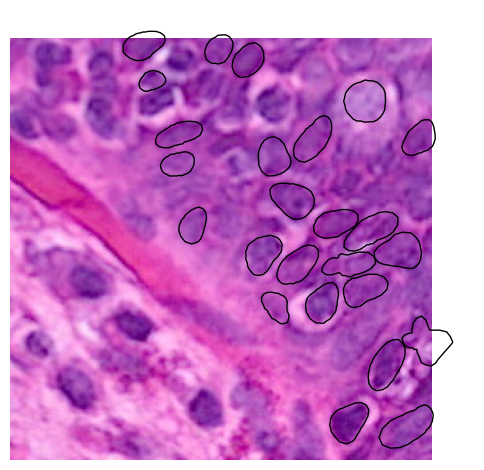

In [97]:
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import translate
from PIL import Image
import pandas as pd

# choose patch
patch_id = "patch_8042.png"  # example
uni_path = "../uni/notebooks/patches"

# load PNG for that patch
patch_img = Image.open(f"{uni_path}/{person}/{patch_id}")

# load tissue_positions.parquet
positions = pd.read_csv(f"../uni/notebooks/metadata/WSI_patch_metadata.csv")
positions = positions.set_index(["Slide_ID", "Patch_ID"])


# lookup offset (top-left corner in global coordinates)
offset_x, offset_y = positions.loc[(person, patch_id), ["X", "Y"]]
print(offset_x, offset_y)


##################### Get Nuclei
# extract nuclei belonging to this patch
nuclei = adata_filtered_nuclei.obs.query("Patch_ID == @patch_id")

# make it a GeoDataFrame
gdf = gpd.GeoDataFrame(nuclei, geometry="geometry")

# shift geometries into patch coordinate system (subtract global offset)
gdf_shifted = gdf.copy()
gdf_shifted["geometry"] = gdf_shifted["geometry"].translate(
    xoff=-offset_x,
    yoff=-offset_y
)


##################### Plotting
fig, ax = plt.subplots(figsize=(6,6))

# show patch
ax.imshow(patch_img)

# overlay nuclei polygons
gdf_shifted.boundary.plot(ax=ax, edgecolor="black", linewidth=1)

plt.axis("off")
plt.show()


In [7]:
nuclei_positions

,id,geometry
5,ID_52421,"POLYGON ((14490.007 14852.000, 14490.093 14853..."
13,ID_52429,"POLYGON ((14409.892 14808.000, 14408.815 14810..."
23,ID_52439,"POLYGON ((14437.344 14816.000, 14434.664 14818..."
31,ID_52447,"POLYGON ((14055.935 14792.000, 14055.610 14793..."
35,ID_52451,"POLYGON ((14464.044 14820.000, 14464.270 14822..."
...,...,...
289375,ID_735550,"POLYGON ((23650.012 36770.000, 23649.842 36772..."
289378,ID_735647,"POLYGON ((23570.196 36782.000, 23568.974 36783..."
289383,ID_735866,"POLYGON ((21905.758 36780.000, 21906.443 36782..."
289391,ID_736660,"POLYGON ((23536.900 36800.000, 23537.887 36801..."
